In [1]:
import torch 
import open_clip
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

In [1]:
import torch 

In [2]:
import open_clip

In [3]:
import pandas as pd

In [4]:
from PIL import Image

In [5]:
import matplotlib.pyplot as plt

In [6]:
df =  pd.read_csv("../data/processed/image_metadata.csv")

In [7]:
import torch
import open_clip

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="laion2b_s34b_b79k",
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

print("Model loaded successfully!")

PyTorch: 2.13.0+cpu
CUDA available: False
Model loaded successfully!


In [8]:
model, _,preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="laion2b_s34b_b79k"

)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768

In [10]:
print(model)

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768

In [11]:
sample =  df.sample(1).iloc[0]
image = preprocess(Image.open(sample.path)).unsqueeze(0).to(device)

In [12]:
with torch.no_grad():
    embedding =  model.encode_image(image)

In [13]:
embedding.shape

torch.Size([1, 512])

In [14]:
print(model)

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768

In [15]:
print(type(preprocess))

<class 'torchvision.transforms.transforms.Compose'>


In [16]:
sample = df.iloc[0]
sample

room                                                     bathroom
style                                                        boho
path            C:\Users\Khushi Trivedi\visual-retrieval-syste...
width                                                         236
height                                                        421
aspect_ratio                                              0.56057
Name: 0, dtype: object

In [17]:
image = preprocess(Image.open(sample.path)).unsqueeze(0).to(device)

In [18]:
with torch.no_grad():
    embedding = model.encode_image(image)

In [19]:
embedding.shape 

torch.Size([1, 512])

In [20]:
embedding

tensor([[ 5.4683e-01,  3.1386e+00,  1.1553e-01,  6.1349e-01,  2.4250e-01,
          2.1317e-01, -3.6461e-01, -1.2215e-02,  5.1530e-01,  5.9486e-01,
         -1.4026e-01, -2.4064e-01, -2.7091e-01,  3.7439e-01, -2.6542e-01,
         -1.1256e-01, -3.6470e-01, -2.5491e-01, -3.2852e-02,  2.0062e-01,
         -4.7308e-01,  3.4867e-01, -3.5694e-01,  5.9060e-02,  4.0735e-01,
          3.2536e-01, -2.5896e-01,  8.0967e-01, -2.9418e-01, -4.7158e-01,
          3.1992e-01,  7.1669e-01,  7.7415e-02,  3.8135e-01, -2.5327e-01,
         -3.8194e-01,  1.2989e-01,  2.8632e-01,  2.2057e-01,  1.6194e-01,
          1.5143e-01,  4.4274e-02, -3.6213e-01, -2.6991e-01,  4.6075e-02,
         -1.5158e-01,  3.4350e-01,  4.3372e-01, -2.7737e-01, -1.0946e-01,
          8.4341e-02, -3.4596e-01,  8.2701e-02,  1.6364e-01, -4.0742e-01,
          5.4961e-01,  1.3550e-01, -4.8094e-02, -6.1234e-01,  3.0400e-01,
         -5.2116e-01, -7.0437e-01, -1.7280e-01, -4.5309e-01,  2.3636e-01,
         -7.0263e-02,  9.7030e-02,  2.

In [21]:
type(embedding)

torch.Tensor

In [22]:
embedding.numel()

512

In [23]:
def get_clip_embedding(image_path):
    image = preprocess(Image.open(image_path)).unsqueeze(0).to(device)
    with torch.no_grad():
        embedding = model.encode_image(image)

    return embedding.squeeze(0).cpu()

In [24]:
embedding =  get_clip_embedding(sample.path)

print(embedding.shape)
print(embedding[:10])

torch.Size([512])
tensor([ 0.5468,  3.1386,  0.1155,  0.6135,  0.2425,  0.2132, -0.3646, -0.0122,
         0.5153,  0.5949])


In [25]:
df.sample(10)

,room,style,path,width,height,aspect_ratio
1731,kitchen,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,235,298,0.788591
2598,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,341,0.692082
2672,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
1866,kitchen,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
1200,bedroom,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,235,333,0.705706
2586,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,295,0.800000
1950,kitchen,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
3300,living_room,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
754,bedroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
2819,kitchen,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667


In [26]:
a = df.iloc[105]
b = df.iloc[411]
c = df.iloc[980]

In [27]:
emb_a = get_clip_embedding(a.path)
emb_b = get_clip_embedding(b.path)
emb_c = get_clip_embedding(c.path)

In [28]:
import torch.nn.functional as F 

In [29]:
sim_ab = F.cosine_similarity(
    emb_a.unsqueeze(0),
    emb_b.unsqueeze(0)
)

sim_ac = F.cosine_similarity(
    emb_a.unsqueeze(0),
    emb_c.unsqueeze(0)
)

In [30]:
print("Bedroom vs Bedroom:", sim_ab.item())
print("Bedroom vs Kitchen:", sim_ac.item())

Bedroom vs Bedroom: 0.5661317110061646
Bedroom vs Kitchen: 0.4351038336753845


In [31]:
def show_image(image_path, title = None):
    image =  Image.open(image_path)

    plt.figure(figsize=(4,4))
    plt.imshow(image)
    plt.axis("off")

    if title:
        plt.title(title)

    plt.show()

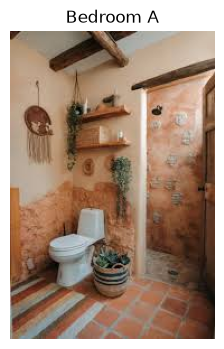

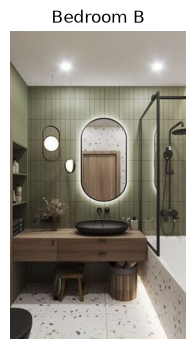

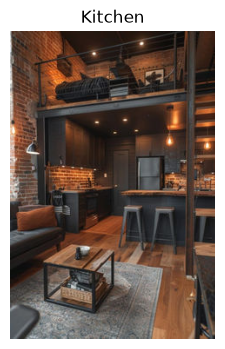

In [32]:
show_image(a.path, "Bedroom A")
show_image(b.path, "Bedroom B")
show_image(c.path, "Kitchen")

In [33]:
df[df["room"] == "bedroom"].sample(5)

,room,style,path,width,height,aspect_ratio
1426,bedroom,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
1143,bedroom,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,235,344,0.683140
1401,bedroom,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,314,0.751592
826,bedroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
1118,bedroom,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,446,0.529148


In [34]:
df[df["room"] == "bathroom"].sample(5)

,room,style,path,width,height,aspect_ratio
392,bathroom,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
658,bathroom,scandinavian,C:\Users\Khushi Trivedi\visual-retrieval-syste...,235,327,0.718654
420,bathroom,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
87,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,295,0.800000
371,bathroom,minimalist,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,419,0.563246


In [35]:
df[df["room"] == "living_room"].sample(5)

,room,style,path,width,height,aspect_ratio
3383,living_room,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,314,0.751592
3399,living_room,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,295,0.800000
3353,living_room,industrial,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
3254,living_room,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,354,0.666667
3782,living_room,modern,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,295,0.800000


In [37]:
print("A:", a.room, "|", a.style)
print("B:", b.room, "|", b.style)
print("C:", c.room, "|", c.style)

A: bathroom | boho
B: bathroom | minimalist
C: bedroom | industrial


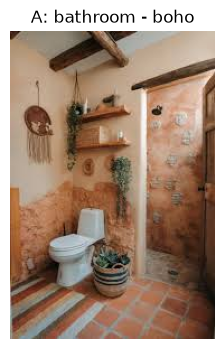

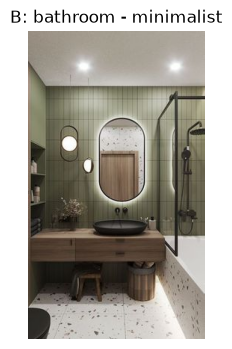

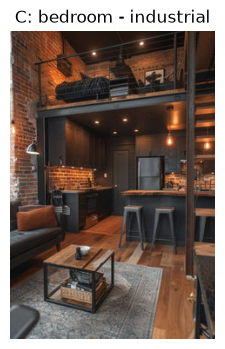

In [38]:
show_image(a.path, f"A: {a.room} - {a.style}")
show_image(b.path, f"B: {b.room} - {b.style}")
show_image(c.path, f"C: {c.room} - {c.style}")

In [39]:
emb_a = get_clip_embedding(a.path)
emb_b = get_clip_embedding(b.path)
emb_c = get_clip_embedding(c.path)

In [40]:
import torch.nn.functional as F

sim_ab = F.cosine_similarity(
    emb_a.unsqueeze(0),
    emb_b.unsqueeze(0)
)

sim_ac = F.cosine_similarity(
    emb_a.unsqueeze(0),
    emb_c.unsqueeze(0)
)

print("Bathroom vs Bathroom:", sim_ab.item())
print("Bathroom vs Bedroom:", sim_ac.item())

Bathroom vs Bathroom: 0.5661317110061646
Bathroom vs Bedroom: 0.4351038336753845


In [41]:
def get_clip_embeddings_batch(image_paths):
    images = []

    for image_path in image_paths:
        image = preprocess(Image.open(image_path).convert("RGB"))
        images.append(image)

    batch = torch.stack(images).to(device)

    with torch.no_grad():
        embeddings = model.encode_image(batch)

    return embeddings.cpu()

In [42]:
test_paths = df["path"].iloc[:8].tolist()

test_embeddings = get_clip_embeddings_batch(test_paths)

print(test_embeddings.shape)

torch.Size([8, 512])


In [43]:
print(test_embeddings.dtype)
print(test_embeddings[0][:10])

torch.float32
tensor([ 0.5468,  3.1386,  0.1155,  0.6135,  0.2425,  0.2132, -0.3646, -0.0122,
         0.5153,  0.5949])


In [44]:
print(torch.isnan(test_embeddings).any())

tensor(False)


In [45]:
batch_size = 32

all_embeddings = []

for start in range(0, len(df), batch_size):
    batch_paths = df["path"].iloc[start:start + batch_size].tolist()

    batch_embeddings = get_clip_embeddings_batch(batch_paths)

    all_embeddings.append(batch_embeddings)

    print(f"Processed {min(start + batch_size, len(df))}/{len(df)}")

Processed 32/4139
Processed 64/4139
Processed 96/4139
Processed 128/4139
Processed 160/4139
Processed 192/4139
Processed 224/4139
Processed 256/4139
Processed 288/4139
Processed 320/4139
Processed 352/4139
Processed 384/4139
Processed 416/4139
Processed 448/4139
Processed 480/4139
Processed 512/4139
Processed 544/4139
Processed 576/4139
Processed 608/4139
Processed 640/4139
Processed 672/4139
Processed 704/4139
Processed 736/4139
Processed 768/4139
Processed 800/4139
Processed 832/4139
Processed 864/4139
Processed 896/4139
Processed 928/4139
Processed 960/4139
Processed 992/4139
Processed 1024/4139
Processed 1056/4139
Processed 1088/4139
Processed 1120/4139
Processed 1152/4139
Processed 1184/4139
Processed 1216/4139
Processed 1248/4139
Processed 1280/4139
Processed 1312/4139
Processed 1344/4139
Processed 1376/4139
Processed 1408/4139
Processed 1440/4139
Processed 1472/4139
Processed 1504/4139
Processed 1536/4139
Processed 1568/4139
Processed 1600/4139
Processed 1632/4139
Processed 1664

In [47]:
all_embeddings = torch.cat(all_embeddings, dim=0)

print(all_embeddings.shape)

torch.Size([4139, 512])


In [48]:
all_embeddings = all_embeddings / all_embeddings.norm(
    dim=1,
    keepdim=True
)

In [49]:
print(all_embeddings.shape)
print(all_embeddings[0].norm())

torch.Size([4139, 512])
tensor(1.)


In [50]:
import os

os.makedirs("../data/embeddings", exist_ok=True)

In [51]:
torch.save(
    all_embeddings,
    "../data/embeddings/clip_embeddings.pt"
)

In [52]:
stored_embeddings = torch.load(
    "../data/embeddings/clip_embeddings.pt"
)

print(stored_embeddings.shape)

torch.Size([4139, 512])


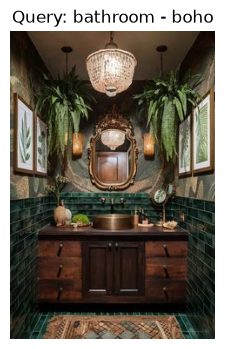

In [53]:
query_index = 100

query_path = df.iloc[query_index].path

show_image(
    query_path,
    f"Query: {df.iloc[query_index].room} - {df.iloc[query_index].style}"
)

In [54]:
query_embedding = get_clip_embedding(query_path)

In [55]:
query_embedding = query_embedding / query_embedding.norm()

In [56]:
similarities = stored_embeddings @ query_embedding

In [57]:
print(similarities.shape)

torch.Size([4139])


In [61]:
similarities[query_index] = -1
top_scores, top_indices = torch.topk(similarities, k=5)

print(top_indices)
print(top_scores)

tensor([ 56,  28,  54,  24, 504])
tensor([0.8475, 0.8326, 0.8288, 0.8273, 0.8211])


1. bathroom | boho | similarity=0.8475


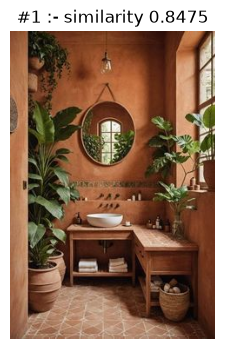

2. bathroom | boho | similarity=0.8326


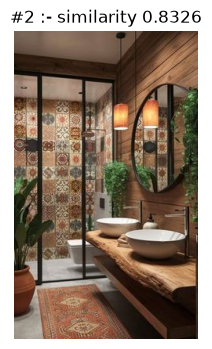

3. bathroom | boho | similarity=0.8288


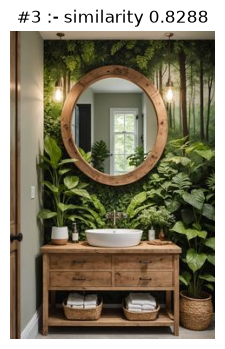

4. bathroom | boho | similarity=0.8273


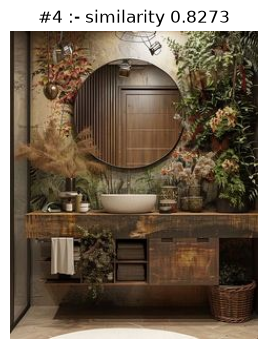

5. bathroom | modern | similarity=0.8211


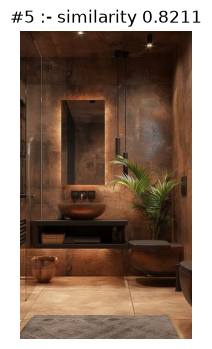

In [63]:
for rank, (index, score) in enumerate(
    zip(top_indices, top_scores), start=1
):
    row = df.iloc[index.item()]

    print(
        f"{rank}. "
        f"{row.room} | {row.style} | "
        f"similarity={score.item():.4f}"
    )

    show_image(
        row.path,
        f"#{rank} :- similarity {score.item():.4f}"
    )

In [64]:
def retrieve_similar_images(query_path, embeddings, df, top_k=5):
    # Generate query embedding
    query_embedding = get_clip_embedding(query_path)

    # Normalize
    query_embedding = query_embedding / query_embedding.norm()

    # Calculate similarity with every stored image
    similarities = embeddings @ query_embedding

    # If query is already in our dataset, exclude itself
    matches = df.index[df["path"] == query_path].tolist()

    if matches:
        similarities[matches[0]] = -1

    # Get top results
    top_scores, top_indices = torch.topk(similarities, k=top_k)

    return top_indices, top_scores

In [65]:
top_indices, top_scores = retrieve_similar_images(
    query_path,
    stored_embeddings,
    df,
    top_k=5
)

1. bathroom | boho | similarity=0.8475


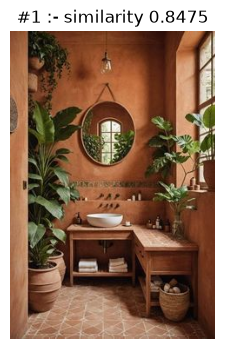

2. bathroom | boho | similarity=0.8326


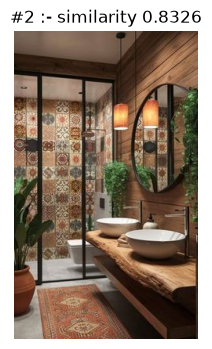

3. bathroom | boho | similarity=0.8288


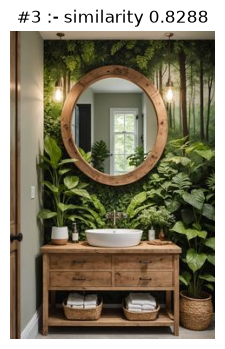

4. bathroom | boho | similarity=0.8273


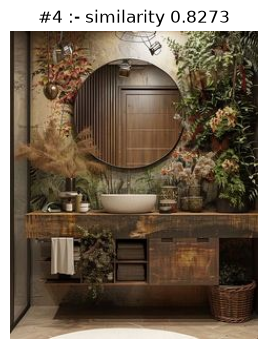

5. bathroom | modern | similarity=0.8211


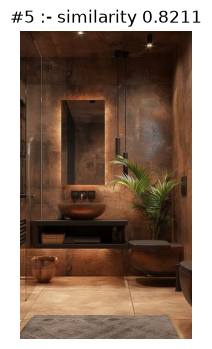

In [67]:
for rank, (index, score) in enumerate(
    zip(top_indices, top_scores), start=1
):
    row = df.iloc[index.item()]

    print(
        f"{rank}. {row.room} | {row.style} | "
        f"similarity={score.item():.4f}"
    )

    show_image(
        row.path,
        f"#{rank} :- similarity {score.item():.4f}"
    )